# Siparişler - `review_score` Çok Değişkenli Regresyonu

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Import modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

⚠️ Devam etmeden önce:
* 💾 Önceki ünitenin Siparişler çözümünü indirin
* 👥 `order_solution.py`'nin içeriğini `olist/order.py` dosyasına kopyalayıp yapıştırın

⚠️ `olist` havuzunuzda `order.py` dosyasındaki kod değişikliklerini commit etmeyi unutmayın!

👇 Öncelikle `orders` veri setini içeri aktarın

In [23]:
from olist.order import Order

orders = Order().get_training_data(
    with_distance_seller_customer=True
)

print("Veri boyutu:", orders.shape)
orders.head()

Veri boyutu: (96353, 13)


,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value,distance_seller_customer
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0,0,4,1,1,29.99,8.72,18.576110
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0,0,4,1,1,118.70,22.76,851.495069
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1,0,5,1,1,159.90,19.22,514.410666
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1,0,5,1,1,45.00,27.20,1822.226336
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1,0,5,1,1,19.90,8.72,29.676625


In [4]:
import inspect

print("Dosya:", inspect.getfile(Order))
print("Metot:", inspect.signature(Order.get_training_data))

Dosya: /home/burak_gokce/code/Burak-Gokce/data-orders/olist/order.py
Metot: (self)


In [5]:
orders = Order().get_training_data()

print("Veri boyutu:", orders.shape)
print("Sütunlar:", orders.columns.tolist())

Veri boyutu: (96353, 12)
Sütunlar: ['order_id', 'wait_time', 'expected_wait_time', 'delay_vs_expected', 'order_status', 'dim_is_five_star', 'dim_is_one_star', 'review_score', 'number_of_items', 'number_of_sellers', 'price', 'freight_value']


In [6]:
import inspect

print(inspect.getsource(Order))

class Order:

    def __init__(self):
        self.data = Olist().get_data()

    def get_wait_time(self):

        orders = self.data["orders"].copy()

        orders = orders[
            orders["order_status"] == "delivered"
        ].copy()

        date_columns = [
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]

        for col in date_columns:
            orders[col] = pd.to_datetime(orders[col])

        orders["wait_time"] = (
            orders["order_delivered_customer_date"]
            - orders["order_purchase_timestamp"]
        ).dt.total_seconds() / (24 * 60 * 60)

        orders["expected_wait_time"] = (
            orders["order_estimated_delivery_date"]
            - orders["order_purchase_timestamp"]
        ).dt.total_seconds() / (24 * 60 * 60)

        orders["delay_vs_expected"] = (
            orders["wait_time"]
            - orders["expected_wait_time"]
        ).clip(lo

In [7]:
olist = Order()

print("Mevcut tablolar:")
print(list(olist.data.keys()))

Mevcut tablolar:
['sellers', 'customers', 'product_category_name_translation', 'order_payments', 'order_items', 'products', 'geolocation', 'order_reviews', 'orders']


In [8]:
for table in ["orders", "order_items", "sellers", "customers", "geolocation"]:
    print(f"\n{table}:")
    print(olist.data[table].columns.tolist())


orders:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

order_items:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

sellers:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

customers:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

geolocation:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


In [9]:
geo = olist.data["geolocation"].copy()

geo_unique = (
    geo.groupby("geolocation_zip_code_prefix")[
        ["geolocation_lat", "geolocation_lng"]
    ]
    .mean()
    .reset_index()
)

print("Orijinal geolocation:", geo.shape)
print("Tekilleştirilmiş geolocation:", geo_unique.shape)

geo_unique.head()

Orijinal geolocation: (1000163, 5)
Tekilleştirilmiş geolocation: (19015, 3)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.550190,-46.634024
1,1002,-23.548146,-46.634979
2,1003,-23.548994,-46.635731
3,1004,-23.549799,-46.634757
4,1005,-23.549456,-46.636733


In [10]:
customers = olist.data["customers"].copy()

customers_geo = customers.merge(
    geo_unique,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)

customers_geo = customers_geo.rename(columns={
    "geolocation_lat": "customer_lat",
    "geolocation_lng": "customer_lng"
})

print("Orijinal müşteri sayısı:", len(customers))
print("Birleştirme sonrası:", len(customers_geo))

print("\nEksik koordinat sayıları:")
print(customers_geo[["customer_lat", "customer_lng"]].isna().sum())

customers_geo.head()

Orijinal müşteri sayısı: 99441
Birleştirme sonrası: 99441

Eksik koordinat sayıları:
customer_lat    278
customer_lng    278
dtype: int64


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_zip_code_prefix,customer_lat,customer_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,14409.0,-20.498489,-47.396929
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,9790.0,-23.727992,-46.542848
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,1151.0,-23.531642,-46.656289
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,8775.0,-23.499702,-46.185233
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,13056.0,-22.975100,-47.142925


In [11]:
sellers = olist.data["sellers"].copy()

sellers_geo = sellers.merge(
    geo_unique,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)

sellers_geo = sellers_geo.rename(columns={
    "geolocation_lat": "seller_lat",
    "geolocation_lng": "seller_lng"
})

print("Orijinal satıcı sayısı:", len(sellers))
print("Birleştirme sonrası:", len(sellers_geo))

print("\nEksik koordinat sayıları:")
print(sellers_geo[["seller_lat", "seller_lng"]].isna().sum())

sellers_geo.head()

Orijinal satıcı sayısı: 3095
Birleştirme sonrası: 3095

Eksik koordinat sayıları:
seller_lat    7
seller_lng    7
dtype: int64


,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,seller_lat,seller_lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,13023.0,-22.893848,-47.061337
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,13844.0,-22.383437,-46.947927
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,20031.0,-22.909572,-43.177703
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,4195.0,-23.657242,-46.612831
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,12914.0,-22.964803,-46.534419


In [12]:
order_locations = (
    olist.data["orders"][["order_id", "customer_id"]]
    .merge(
        olist.data["order_items"][["order_id", "seller_id"]],
        on="order_id",
        how="inner"
    )
    .merge(
        customers_geo[["customer_id", "customer_lat", "customer_lng"]],
        on="customer_id",
        how="left"
    )
    .merge(
        sellers_geo[["seller_id", "seller_lat", "seller_lng"]],
        on="seller_id",
        how="left"
    )
)

print("Veri boyutu:", order_locations.shape)
print("Benzersiz sipariş sayısı:", order_locations["order_id"].nunique())

print("\nEksik koordinatlar:")
print(
    order_locations[
        ["customer_lat", "customer_lng", "seller_lat", "seller_lng"]
    ].isna().sum()
)

order_locations.head()

Veri boyutu: (112650, 7)
Benzersiz sipariş sayısı: 98666

Eksik koordinatlar:
customer_lat    302
customer_lng    302
seller_lat      253
seller_lng      253
dtype: int64


,order_id,customer_id,seller_id,customer_lat,customer_lng,seller_lat,seller_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,3504c0cb71d7fa48d967e0e4c94d59d9,-23.576983,-46.587161,-23.680729,-46.444238
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,289cdb325fb7e7f891c38608bf9e0962,-12.177924,-44.660711,-19.807681,-43.980427
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,4869f7a5dfa277a7dca6462dcf3b52b2,-16.745150,-48.514783,-21.363502,-48.229601
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,66922902710d126a0e7d26b0e3805106,-5.774190,-35.271143,-19.837682,-43.924053
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2c9e548be18521d1c43cde1c582c6de8,-23.676370,-46.514627,-23.543395,-46.262086


In [13]:
import numpy as np

lat1 = np.radians(order_locations["customer_lat"])
lon1 = np.radians(order_locations["customer_lng"])

lat2 = np.radians(order_locations["seller_lat"])
lon2 = np.radians(order_locations["seller_lng"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

order_locations["distance_seller_customer"] = 6371 * c

print("Mesafe istatistikleri (km):")
print(order_locations["distance_seller_customer"].describe())

print("\nMesafesi hesaplanamayan satır:")
print(order_locations["distance_seller_customer"].isna().sum())

Mesafe istatistikleri (km):
count    112096.000000
mean        596.959183
std         589.978820
min           0.000000
25%         184.065837
50%         431.635462
75%         792.275606
max        8677.911622
Name: distance_seller_customer, dtype: float64

Mesafesi hesaplanamayan satır:
554


In [14]:
order_distances = (
    order_locations
    .groupby("order_id", as_index=False)
    .agg(
        distance_seller_customer=(
            "distance_seller_customer", "mean"
        )
    )
)

print("Veri boyutu:", order_distances.shape)

print("\nBenzersiz sipariş sayısı:")
print(order_distances["order_id"].nunique())

print("\nEksik mesafe sayısı:")
print(order_distances["distance_seller_customer"].isna().sum())

order_distances.head()

Veri boyutu: (98666, 2)

Benzersiz sipariş sayısı:
98666

Eksik mesafe sayısı:
489


,order_id,distance_seller_customer
0,00010242fe8c5a6d1ba2dd792cb16214,301.504681
1,00018f77f2f0320c557190d7a144bdd3,585.563937
2,000229ec398224ef6ca0657da4fc703e,312.343511
3,00024acbcdf0a6daa1e931b038114c75,293.168420
4,00042b26cf59d7ce69dfabb4e55b4fd9,646.163463


In [16]:
print("Toplam satır:", len(orders))
print("Benzersiz sipariş:", orders["order_id"].nunique())

print("\nTekrarlanan order_id sayısı:")
print(orders["order_id"].duplicated().sum())

print("\nEn sık tekrarlanan siparişler:")
print(orders["order_id"].value_counts().head(10))

Toplam satır: 96353
Benzersiz sipariş: 95824

Tekrarlanan order_id sayısı:
529

En sık tekrarlanan siparişler:
order_id
03c939fd7fd3b38f8485a0f95798f1f6    3
c88b1d1b157a9999ce368f218a407141    3
8e17072ec97ce29f0e1f111e598b0c85    3
df56136b8031ecd28e200bb18e6ddb2e    3
cf73e2cb1f4a9480ed70c154da3d954a    2
6525d9ab0bff6133c63e9c0cfa55bfbd    2
33f1e992ba3e439bfd0d432164a3d44a    2
9eb9610a7e3c04e7ab0298d704c383dc    2
c86cd0844d36479f7e7adb1edd5e59d3    2
ca263afd88a8a1200605adbd4b63cd7d    2
Name: count, dtype: int64


In [17]:
reviews = olist.data["order_reviews"]

print("Review tablosundaki toplam satır:", len(reviews))
print("Benzersiz sipariş:", reviews["order_id"].nunique())

print("\nTekrarlanan review satırları:")
print(reviews["order_id"].duplicated().sum())

print("\nÖrnek siparişin değerlendirmeleri:")
print(
    reviews.loc[
        reviews["order_id"] == "03c939fd7fd3b38f8485a0f95798f1f6",
        ["order_id", "review_score"]
    ]
)

Review tablosundaki toplam satır: 99224
Benzersiz sipariş: 98673

Tekrarlanan review satırları:
551

Örnek siparişin değerlendirmeleri:
                               order_id  review_score
8273   03c939fd7fd3b38f8485a0f95798f1f6             3
51527  03c939fd7fd3b38f8485a0f95798f1f6             4
69438  03c939fd7fd3b38f8485a0f95798f1f6             3


In [18]:
reviews_unique = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

print("Tekilleştirilmiş review boyutu:", reviews_unique.shape)

print("\nÖrnek siparişin ortalama puanı:")
print(
    reviews_unique.loc[
        reviews_unique["order_id"] ==
        "03c939fd7fd3b38f8485a0f95798f1f6"
    ]
)

print("\nTekrarlanan sipariş sayısı:")
print(reviews_unique["order_id"].duplicated().sum())

Tekilleştirilmiş review boyutu: (98673, 2)

Örnek siparişin ortalama puanı:
                              order_id  review_score
1455  03c939fd7fd3b38f8485a0f95798f1f6      3.333333

Tekrarlanan sipariş sayısı:
0


In [19]:
review_counts = reviews.groupby("order_id")["review_score"].agg(
    review_count="size",
    unique_scores="nunique"
)

print("Birden fazla değerlendirmesi olan sipariş:")
print((review_counts["review_count"] > 1).sum())

print("\nFarklı puanlar içeren sipariş:")
print((review_counts["unique_scores"] > 1).sum())

print("\nAynı puanın tekrarlandığı sipariş:")
print(
    (
        (review_counts["review_count"] > 1)
        & (review_counts["unique_scores"] == 1)
    ).sum()
)

Birden fazla değerlendirmesi olan sipariş:
547

Farklı puanlar içeren sipariş:
202

Aynı puanın tekrarlandığı sipariş:
345


In [20]:
orders_with_distance = orders.merge(
    order_distances,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Orijinal veri boyutu:", orders.shape)
print("Yeni veri boyutu:", orders_with_distance.shape)

print("\nEksik mesafe sayısı:")
print(
    orders_with_distance["distance_seller_customer"]
    .isna()
    .sum()
)

orders_with_distance.head()

Orijinal veri boyutu: (96353, 12)
Yeni veri boyutu: (96353, 13)

Eksik mesafe sayısı:
481


,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value,distance_seller_customer
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0,0,4,1,1,29.99,8.72,18.576110
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0,0,4,1,1,118.70,22.76,851.495069
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1,0,5,1,1,159.90,19.22,514.410666
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1,0,5,1,1,45.00,27.20,1822.226336
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1,0,5,1,1,19.90,8.72,29.676625


In [21]:
import importlib
import olist.order

importlib.reload(olist.order)

Order = olist.order.Order

distance_test = Order().get_distance_seller_customer()

print("Veri boyutu:", distance_test.shape)
print("Eksik mesafe:", distance_test["distance_seller_customer"].isna().sum())

distance_test.head()

Veri boyutu: (98666, 2)
Eksik mesafe: 489


,order_id,distance_seller_customer
0,00010242fe8c5a6d1ba2dd792cb16214,301.504681
1,00018f77f2f0320c557190d7a144bdd3,585.563937
2,000229ec398224ef6ca0657da4fc703e,312.343511
3,00024acbcdf0a6daa1e931b038114c75,293.168420
4,00042b26cf59d7ce69dfabb4e55b4fd9,646.163463


In [22]:
import importlib
import olist.order

# Güncel order.py dosyasını yeniden yükle
importlib.reload(olist.order)

Order = olist.order.Order

# Eski kullanım: mesafe olmadan
orders_without_distance = Order().get_training_data()

# Yeni kullanım: mesafe dahil
orders_with_distance = Order().get_training_data(
    with_distance_seller_customer=True
)

print("Eski veri boyutu:", orders_without_distance.shape)
print("Yeni veri boyutu:", orders_with_distance.shape)

print("\nEksik mesafe sayısı:")
print(
    orders_with_distance["distance_seller_customer"]
    .isna().sum()
)

print("\nYeni veri setinin sütunları:")
print(orders_with_distance.columns.tolist())

Eski veri boyutu: (96353, 12)
Yeni veri boyutu: (96353, 13)

Eksik mesafe sayısı:
481

Yeni veri setinin sütunları:
['order_id', 'wait_time', 'expected_wait_time', 'delay_vs_expected', 'order_status', 'dim_is_five_star', 'dim_is_one_star', 'review_score', 'number_of_items', 'number_of_sellers', 'price', 'freight_value', 'distance_seller_customer']


Önceki analizimizi hatırlayalım:

Aşağıdaki 👇 korelasyon matrisi üzerinden, `review_score`'un çoğunlukla iki özellik ile ilişkili olduğunu görebiliriz: `wait_time` ve `delay_vs_expected`. Ancak, bu iki özellik de birbirleriyle yüksek oranda ilişkilidirler.

Bu alıştırmada, bir özelliğin etkisini ayırt etmek için `statsmodels` kullanacağız, **diğer özellikleri sabit tutarak**.

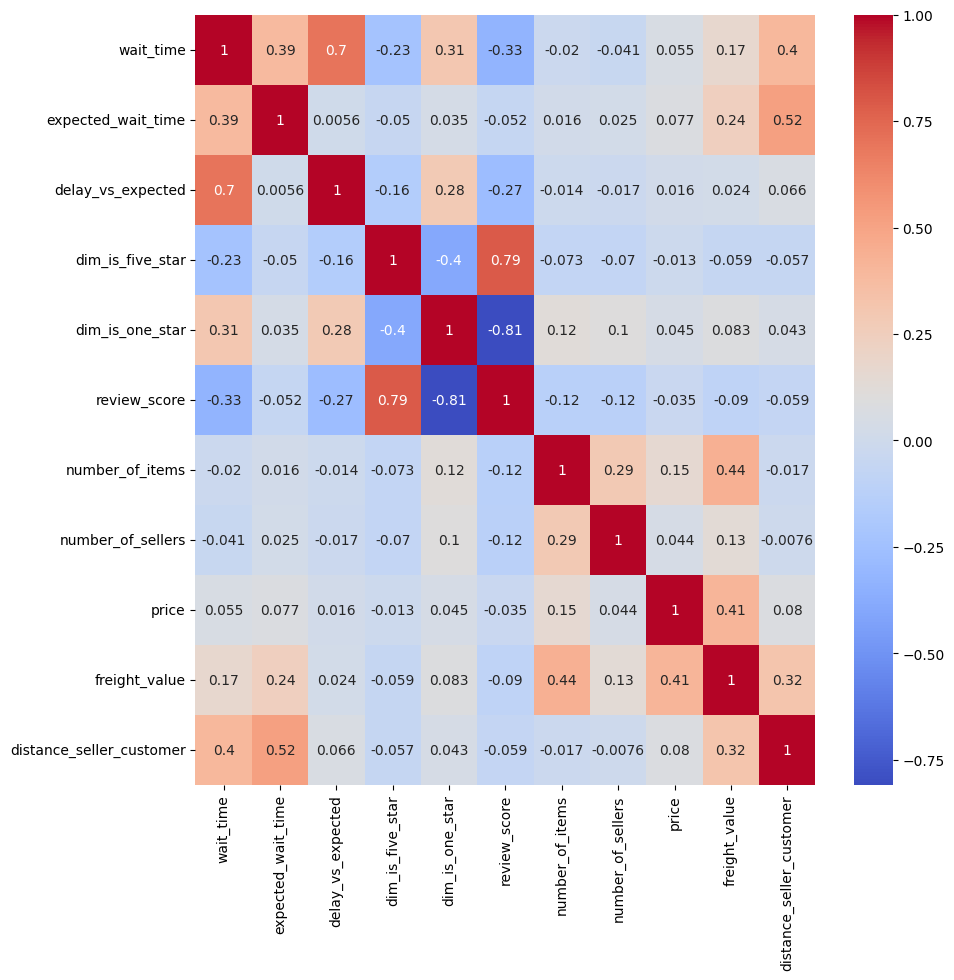

In [24]:
plt.figure(figsize = (10, 10))

sns.heatmap(
    orders.corr(numeric_only=True),
    cmap='coolwarm',
    annot=True,
    annot_kws={"size": 10}
);

## 1 - Tek Değişkenli Regresyon

❓ [statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html) ile `statsmodels.formula.api` kullanarak hızlı bir şekilde şunları oluşturun:
 - `model1`: `review_score`'un `wait_time` üzerinde ols regresyonu
 - `model2`: `review_score`'un `delay_vs_expected` üzerinde ols regresyonu

Her biri için `summary` tablosunu yazdırın ve sonuçları yorumlayin:
- Bu sonuçların seaborn regplot sonuçları ile nasıl eşleştiğini anladığınızdan emin olun
- Regresyon performans metriği `R-squared`, `individual regression coefficients`, `t-values`, `p-values` ve `95% confidence intervals`'ı okuyun

***Model 1***:

In [25]:
import statsmodels.formula.api as smf

model1 = smf.ols(
    formula="review_score ~ wait_time",
    data=orders
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                 1.208e+04
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:47:30   Log-Likelihood:            -1.5519e+05
No. Observations:               96353   AIC:                         3.104e+05
Df Residuals:                   96351   BIC:                         3.104e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7236      0.006    729.482      0.0

***Model 2***:

In [26]:
model2 = smf.ols(
    formula="review_score ~ delay_vs_expected",
    data=orders
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     7715.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:52:07   Log-Likelihood:            -1.5717e+05
No. Observations:               96353   AIC:                         3.143e+05
Df Residuals:                   96351   BIC:                         3.144e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.2124      0.00

## 2 - Çok Değişkenli Regresyon

❓ Siparişe bir gün `delay_vs_expected` eklemenin `review_score` üzerindeki etkisi nedir, **`wait_time` sabit tutarak**? İki özellikten hangisi düşük `review_score` için en açıklayıcıdır?

Bu amaçla, `wait_time` ve `delay_vs_expected`'in özellikler (bağımsız değişkenler) olduğu ve `review_score`'un hedef (bağımlı değişken) olduğu bir OLS modeli `model3`'ü çalıştırın

***Model 3***:

In [27]:
model3 = smf.ols(
    formula="review_score ~ wait_time + delay_vs_expected",
    data=orders
).fit()

print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     6211.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:55:54   Log-Likelihood:            -1.5504e+05
No. Observations:               96353   AIC:                         3.101e+05
Df Residuals:                   96350   BIC:                         3.101e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.6500      0.00

----
👉 Çok değişkenli regresyon, bir özelliğin etkisini izole etmek ve diğer özelliklerin etkisini kontrol etmek için bize izin verir. Bu yeni katsayılara **`kısmi korelasyon katsayıları`** denir. 

❓ Yukarıda *seaborn* ile hesaplanan **basit regresyon** katsayıları ile fark görebilir misiniz? 

❓ `wait_time` ve `delay_vs_expected` için göreceli eğimler hakkında ne söyleyebilirsiniz?

<details>
    <summary>- 💡 Solution 💡-</summary>

- Holding `wait_time` constant, each additional day of `delay` reduces the review_score on average by 0.0205 [0.023 - 0.018] points
- Holding `delay` constant, each additional day of `wait_time` reduces the review_score on average by 0.0383 [0.039 - 0.037] points

Contrary to what was found with the simple bivariate correlation analysis, `delay` is actually less impactful than `wait_time` in driving lower `review_score`! This interesting finding demonstrates the importance of multi-variate regression to remove the potential impact of confounding factors

---
❌ R-squared oldukça düşük: review_score varyasyonlarının en fazla %12'si `wait_time` ve `delay_vs_expected`'in birleşik varyasyonları tarafından açıklanır.

✅ Doğrusal regresyonun açıklanabilirliğini iyileştirmek için regresyonumuza daha fazla özellik eklemeyi deneyelim.

Sonraki adımlarda `orders` veri setinden daha fazla özellik içeren yeni bir OLS `model4` oluşturacağız. Adım adım size rehberlik edeceğiz.

📝 <u>Not</u>: bir **`Çok Değişkenli Doğrusal Regresyon`** aynı zamanda **`Ordinary Least Squares`** yöntemi olarak da adlandırılır çünkü bu modelde **`MSE Ortalama Kare Hatalar`**'ı minimize etmek istiyoruz

***Model 4***:

❓ Hangi özellikleri göz önünde almak istersiniz?

👉 Bu özelliklerle bir `features` DataFrame oluşturun.

- ⚠️ **veri sızıntısı** oluşturmayın: `review_score`'tan doğrudan türetilen özellikleri eklemeyin
- ⚠️ Birbirleriyle mükemmel bir şekilde ilişkili olan iki özellik eklemeyin

In [28]:
feature_columns = [
    "wait_time",
    "delay_vs_expected",
    "number_of_items",
    "number_of_sellers",
    "price",
    "freight_value",
    "distance_seller_customer"
]

features = orders[feature_columns].copy()

print("Özellik veri setinin boyutu:", features.shape)

print("\nEksik değerler:")
print(features.isna().sum())

features.head()

Özellik veri setinin boyutu: (96353, 7)

Eksik değerler:
wait_time                     0
delay_vs_expected             0
number_of_items               0
number_of_sellers             0
price                         0
freight_value                 0
distance_seller_customer    481
dtype: int64


,wait_time,delay_vs_expected,number_of_items,number_of_sellers,price,freight_value,distance_seller_customer
0,8.436574,0.0,1,1,29.99,8.72,18.576110
1,13.782037,0.0,1,1,118.70,22.76,851.495069
2,9.394213,0.0,1,1,159.90,19.22,514.410666
3,13.208750,0.0,1,1,45.00,27.20,1822.226336
4,2.873877,0.0,1,1,19.90,8.72,29.676625


In [29]:
# Model 4 için eksiksiz gözlemleri seçiyoruz
features_clean = features.dropna().copy()

print("Orijinal gözlem sayısı:", len(features))
print("Temizlenmiş gözlem sayısı:", len(features_clean))
print("Çıkarılan gözlem sayısı:", len(features) - len(features_clean))

print("\nKalan eksik değer sayısı:")
print(features_clean.isna().sum().sum())

Orijinal gözlem sayısı: 96353
Temizlenmiş gözlem sayısı: 95872
Çıkarılan gözlem sayısı: 481

Kalan eksik değer sayısı:
0


Sonra, özellikleri "standardize" edeceğiz.

**Bu ne anlama gelir?**

⚖️  Her özellik $X_i$'yi ilgili z-score'una $Z_i = \frac{X_i - \mu_i}{\sigma_i}$ dönüştüreceğiz.

**Neden?**

Bir `çok değişkenli doğrusal regresyon`'da, her özelliğin hedef üzerindeki etkisini ölçmeye çalışıyoruz.
    
⚠️ Ölçek etkileri nedeniyle, bazı özellikler yanlışlıkla diğerlerinden daha önemli olarak görülecektir
    
> Örneğin: "yatak odası sayısı" özelliği 1 ile 5 arasında ve "yüzey" özelliği 20 ile 200 m² arasında ise, bu iki özelliğin aralıkları oldukça farklıdır...

Bu nedenle kısmi regresyon katsayıları $\beta_i$'yi birlikte karşılaştırabilmek için standardize ederiz. Aksi takdirde, $\beta_i$ aynı boyuta sahip olmayacak, yani elmalar (örn. "gün başına review-yıldızlar") ile portakalları (örn. "BRL başına review-yıldızlar") karşılaştırmış olacaksınız!

📅 Makine Öğrenmesi Algoritmalarını keşfettiğimizde, herhangi bir hedefi tahmin etmeye çalışmadan önce bazı ölçekleme işlemleri gerçekleştirmemiz gerekecektir.

👉  Özelliklerinizi standardize edin:

1. `features` DataFrame'inizden başlayın
1. `mean`'i çıkarın
1. Standart sapma `std`'ye bölün.
1. Sonucu `orders_standardized` değişkenine kaydedin.
1. Son olarak, `orders['review_score']` sütununu `orders_standardized`'e kopyalayın.

2. ve 3. adımları basit bir matematiksel işlem olarak yazabilirsiniz, hatta DataFrames ile de. Pandas bunu anlamak için yeterince akıllıdır.

<details>
  <summary><i>İpucu</i></summary>

  ```python
  features - features.mean() / features.std()
  ```

</details>

👉 `model4`'ü oluşturun ve eğitin.

In [30]:
# Bağımsız değişkenleri standartlaştırıyoruz
orders_standardized = (
    features_clean - features_clean.mean()
) / features_clean.std()

# Hedef değişkeni aynı satırlarla eşleştiriyoruz
orders_standardized["review_score"] = orders.loc[
    features_clean.index, "review_score"
]

print("Standartlaştırılmış veri boyutu:", orders_standardized.shape)

print("\nBağımsız değişkenlerin ortalamaları:")
print(orders_standardized[feature_columns].mean().round(4))

print("\nBağımsız değişkenlerin standart sapmaları:")
print(orders_standardized[feature_columns].std().round(4))

orders_standardized.head()

Standartlaştırılmış veri boyutu: (95872, 8)

Bağımsız değişkenlerin ortalamaları:
wait_time                   0.0
delay_vs_expected           0.0
number_of_items            -0.0
number_of_sellers           0.0
price                       0.0
freight_value              -0.0
distance_seller_customer   -0.0
dtype: float64

Bağımsız değişkenlerin standart sapmaları:
wait_time                   1.0
delay_vs_expected           1.0
number_of_items             1.0
number_of_sellers           1.0
price                       1.0
freight_value               1.0
distance_seller_customer    1.0
dtype: float64


,wait_time,delay_vs_expected,number_of_items,number_of_sellers,price,freight_value,distance_seller_customer,review_score
0,-0.431192,-0.161781,-0.264595,-0.112544,-0.513802,-0.652038,-0.981488,4
1,0.134174,-0.161781,-0.264595,-0.112544,-0.086640,0.000467,0.423668,4
2,-0.329907,-0.161781,-0.264595,-0.112544,0.111748,-0.164053,-0.145002,5
3,0.073540,-0.161781,-0.264595,-0.112544,-0.441525,0.206815,2.061317,5
4,-1.019535,-0.161781,-0.264595,-0.112544,-0.562388,-0.652038,-0.962761,5


In [31]:
formula = "review_score ~ " + " + ".join(feature_columns)

model4 = smf.ols(
    formula=formula,
    data=orders_standardized
).fit()

print(model4.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     2322.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:10:55   Log-Likelihood:            -1.5258e+05
No. Observations:               95872   AIC:                         3.052e+05
Df Residuals:                   95864   BIC:                         3.052e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

---
❓ En önemli özellikler nelerdir? (onları iyi görselleştirmek için `.plot(kind='barh')` ile bir çubuk grafik yapın)
- Genel regresyon performansı nasıl değişti?
- Bu regresyon istatistiksel olarak anlamlı mıdır?

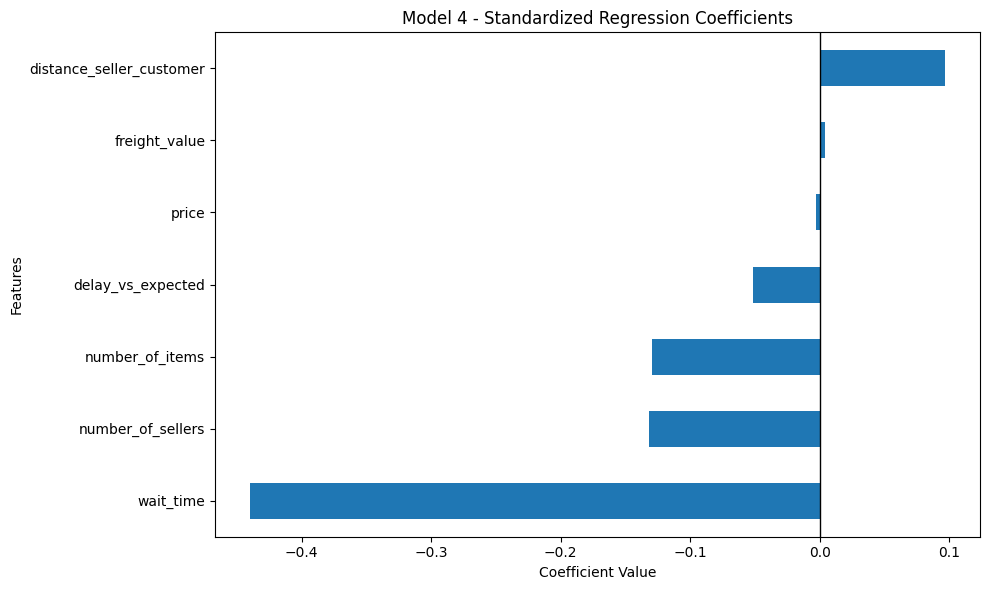

In [32]:
# Sabit terimi (Intercept) hariç tutuyoruz
coefficients = model4.params.drop("Intercept")

# Katsayıları küçükten büyüğe sıralıyoruz
coefficients = coefficients.sort_values()

# Yatay çubuk grafik
plt.figure(figsize=(10, 6))

coefficients.plot(kind="barh")

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Model 4 - Standardized Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

<details>
    <summary>- 💡 Açıklamalar 💡 -</summary>
    

- `wait_time` en büyük açıklayıcı değişkendir
- Tek bir sipariş için ne kadar çok `items` ve `sellers` varsa, `review_score` o kadar düşük görünür
- Mesafe de müşteri memnuniyetinde rol oynar.
- Özellik seçiminize bağlı olarak, `price` ve `freight_value` hakkında p-değerleri çok yüksekse hiçbir sonuca varamayabilirsiniz
    
- Genel olarak, bu çok değişkenli regresyon, F-istatistiği 1'den çok daha büyük olduğu için istatistiksel olarak anlamlı kalır (en az bir özelliğin çok düşük p-değeri vardır)

- R-squared çok fazla artmadı. `review_score`'un açıklanabilirliğinin çoğu orders veri seti dışında yer alır.

⚠️ Gözlem sayısı (n) özellik sayısından (p) çok daha yüksek olduğunda düşük R-squared yaygındır. Böyle regresyonlardan, istatistiksel olarak anlamlı olması koşuluyla yine de ilgili içgörüler elde edilebilir.
</details>



## 3 - Model Performansını Kontrol Edin

⚠️ Regresyon performansı sadece R-squared'i ile ölçülmemelidir!

👀 Her zaman tahminlerin dağılımını, özellikle de kalıntıları görselleştirin.

❓ Kalıntıları hesaplayın.

Kalıntıların ortalamasının 0'a eşit olduğunu görmelisiniz (doğrusal regresyon yapılırken bunu her zaman doğrulayın)

In [33]:
# Model 4'ün tahminleri
predicted_review_score = model4.predict(orders_standardized)

# Gerçek değerler
actual_review_score = orders_standardized["review_score"]

# Kalıntılar = Gerçek - Tahmin
residuals = actual_review_score - predicted_review_score

print("Gözlem sayısı:", len(residuals))
print("Kalıntıların ortalaması:", residuals.mean())
print("Kalıntıların toplamı:", residuals.sum())

residuals.head()

Gözlem sayısı: 95872
Kalıntıların ortalaması: -3.0429152744489256e-14
Kalıntıların toplamı: -2.9173037319196737e-09


0   -0.306315
1   -0.195183
2    0.656989
3    0.617557
4    0.432856
dtype: float64

🧮 İlişkili RMSE'yi hesaplayın.

In [34]:
# RMSE hesaplama
rmse = np.sqrt(np.mean(residuals ** 2))

print("Model 4 RMSE:", rmse)

Model 4 RMSE: 1.1883112206210116


📊 `residuals`'ı bir histogramda çizin.

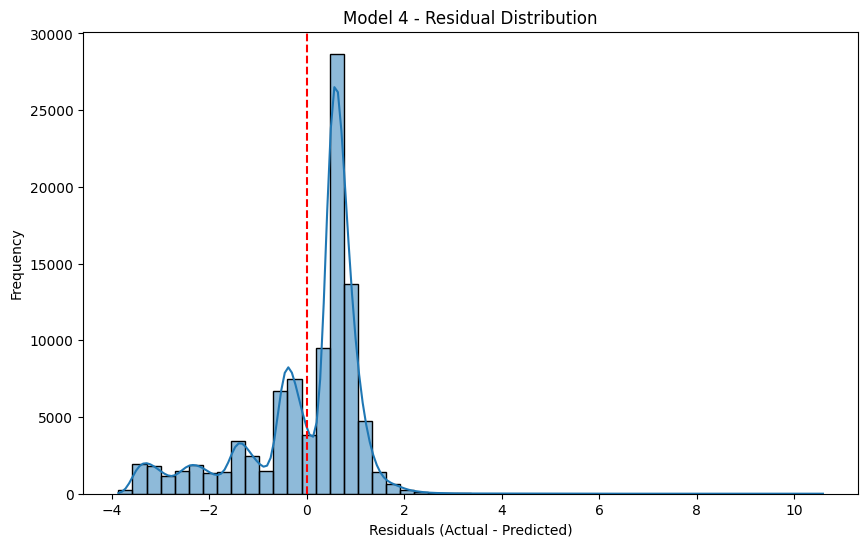

In [35]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(x=0, color="red", linestyle="--")

plt.title("Model 4 - Residual Distribution")
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")

plt.show()

❓ Kalıntıların distplot'unun neden bu kadar garip bir şekle sahip olduğunu tahmin edebilir misiniz?

*İpucu:*<br/>
👉 Aynı grafik üzerinde hem `review_score`'un dağılımını hem de `predicted_review_score`'un dağılımını çizin.

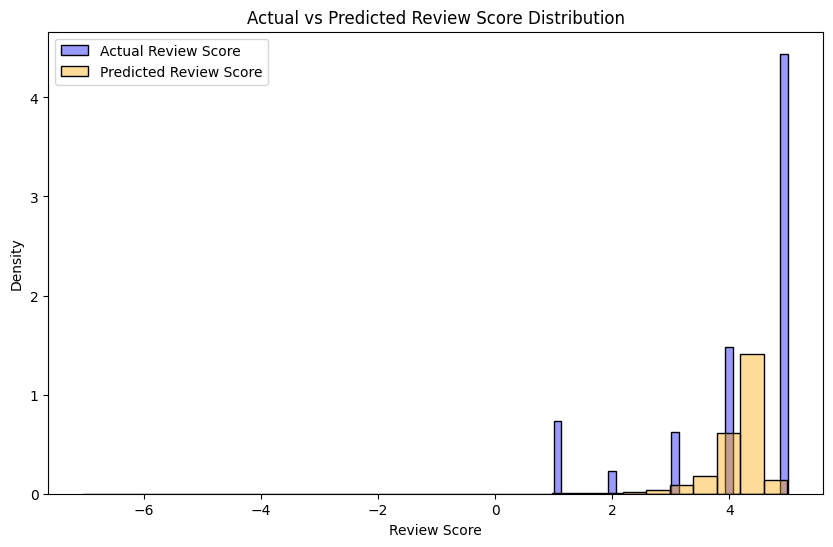

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(
    actual_review_score,
    bins=30,
    stat="density",
    color="blue",
    alpha=0.4,
    label="Actual Review Score"
)

sns.histplot(
    predicted_review_score,
    bins=30,
    stat="density",
    color="orange",
    alpha=0.4,
    label="Predicted Review Score"
)

plt.title("Actual vs Predicted Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Density")

plt.legend()
plt.show()

📈 Aslında, önceki zorlukta `review_score`'un `delay_vs_expected`'e karşı `regresyon çizgisi`'ni zaten çizmiştik.

Bu çizimi yeniden görselleştirmek için aşağıdaki hücreyi çalıştırın:

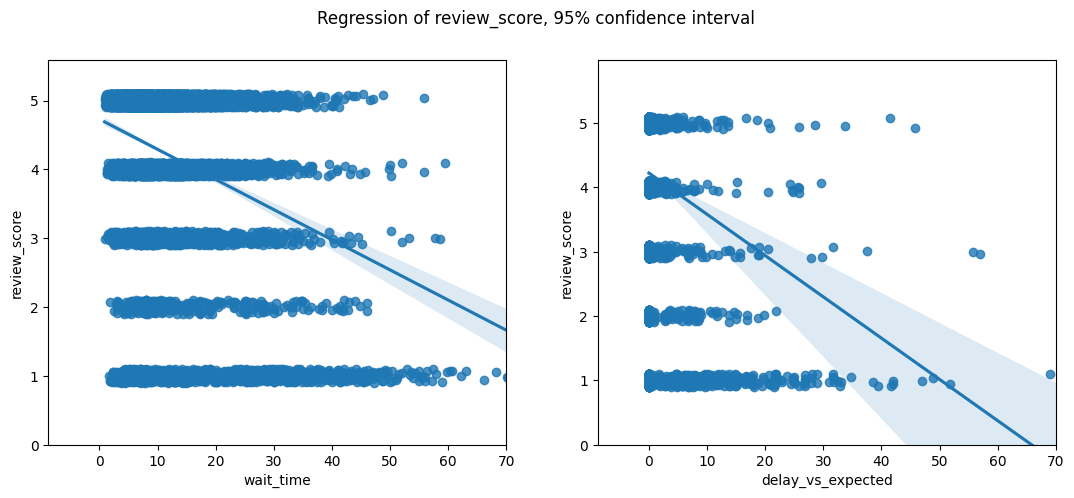

In [37]:
sample = orders.sample(10000, random_state=42)

plt.figure(figsize=(13, 5))
plt.suptitle('Regression of review_score, 95% confidence interval')

plt.subplot(1, 2, 1)
sns.regplot(
    x=sample.wait_time,
    y=sample.review_score,
    y_jitter=.1,
    ci=95
)
plt.xlim(right=70)
plt.ylim(bottom=0)

plt.subplot(1, 2, 2)
sns.regplot(
    x=sample.delay_vs_expected,
    y=sample.review_score,
    y_jitter=.1,
    ci=95
)
plt.xlim(right=70)
plt.ylim(bottom=0)

plt.show()

☝️ Bir siparişin `review_score`'unu onun `wait_time` veya `delay_vs_expected`'ine karşı regrese etmenin zor olduğunu görebilirsiniz çünkü `review_score` ayrı bir sayı olup aynı zamanda bir kategori olarak da yorumlanabilir: 1 (çok kötü), 2 (kötü), 3 (orta), 4 (iyi), 5 (mükemmel).

📅 Sonraki ünitede, adına rağmen bir `Classification Algorithm` olan yeni bir model keşfedeceksiniz: `Logistic Regression` 

☝️ Sonuç olarak, modelimiz iki nedenden dolayı o kadar harika değil:
- İlk olarak, review_scores'un önemli bir kısmını açıklamak için yeterli özelliğimiz olmadığı için (düşük R-squared)
- İkinci olarak, "doğrusal regresyon" işlevini ayrı bir sınıflandırma problemine uydurmaya çalıştığımız için

💡 Bireysel siparişler üzerinde çalışmak ve `wait_time` tabanlı ayrı `review_score`'ları açıklamaya çalışmak yerine, bir sonraki zorlukta siparişleri satıcılar tarafından toplayarak analiz edilmesini satıcı seviyesine yoğunlaştıracağız.

🏁 Harika iş!

💾 İşiniz bittiğinde bu not defterini *kaydetmeyi*, *commit* ve *push* etmeyi unutmayın!